In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import random

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import h5py
path = "/content/drive/My Drive/Datasets/TrainAndTestDataset.mat"

file =h5py.File(path,'r')

In [4]:
X = np.array(file['Xall']).transpose(2,1,0)
y = np.array(file['Yall']).transpose()
labels = np.argmax(y, axis=1)

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp, y_train_lbl, y_temp_lbl = train_test_split(
    X, y, labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test, y_val_lbl, y_test_lbl = train_test_split(
    X_temp, y_temp, y_temp_lbl,
    test_size=0.50,
    stratify=y_temp_lbl,
    random_state=42
)

In [6]:
model = models.Sequential([

    layers.Input(shape=(200,6)),

    # ===== CNN =====
    layers.Conv1D(32, kernel_size=5, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),

    layers.Conv1D(64, kernel_size=3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),

    # ===== BiLSTM =====
    layers.Bidirectional(
        layers.LSTM(128, return_sequences=True)
    ),
    layers.Dropout(0.3),

    layers.Bidirectional(
        layers.LSTM(64)
    ),

    # ===== Classification =====
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(5, activation='softmax')
])

In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 196, 32)        │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 196, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 98, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 96, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 48, 256)        │       197,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 395,173 (1.51 MB)

 Trainable params: 394,725 (1.51 MB)

 Non-trainable params: 448 (1.75 KB)

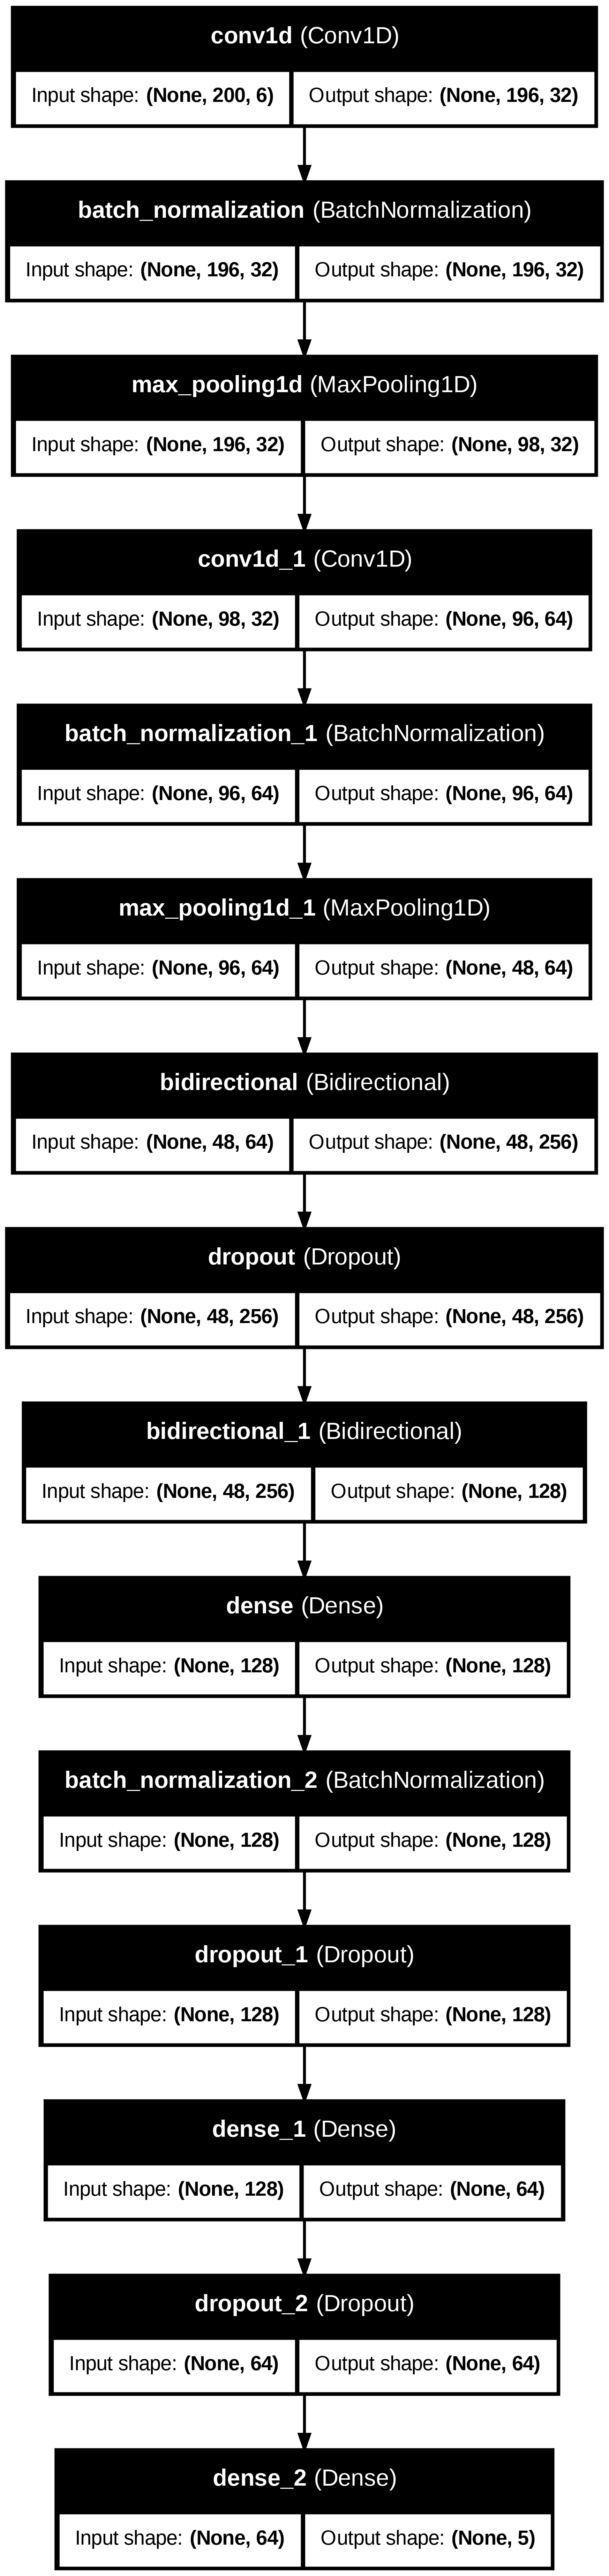

In [11]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    to_file='cnn_bilstm_architecture.png',
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True,
    dpi=300
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 37s 236ms/step - accuracy: 0.6797 - loss: 0.8368 - val_accuracy: 0.6549 - val_loss: 1.0264 - learning_rate: 0.0010
Epoch 2/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 32s 244ms/step - accuracy: 0.8344 - loss: 0.4727 - val_accuracy: 0.8395 - val_loss: 0.4596 - learning_rate: 0.0010
Epoch 3/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 40s 237ms/step - accuracy: 0.8630 - loss: 0.3971 - val_accuracy: 0.8294 - val_loss: 0.4971 - learning_rate: 0.0010
Epoch 4/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 33s 250ms/step - accuracy: 0.8773 - loss: 0.3522 - val_accuracy: 0.9035 - val_loss: 0.2954 - learning_rate: 0.0010
Epoch 5/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 34s 259ms/step - accuracy: 0.8867 - loss: 0.3340 - val_accuracy: 0.8810 - val_loss: 0.3083 - learning_rate: 0.0010
Epoch 6/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 34s 262ms/step - accuracy: 0.8939 - loss: 0.3142 - val_accuracy: 0.8664 - val_loss: 0.3541 - learning_rate: 0.0010
Epoch 7/1000
130/130 ━━━━━━━━━━━━━━━━━━━━ 36s 273ms/step -

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test)

56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.9585 - loss: 0.1604


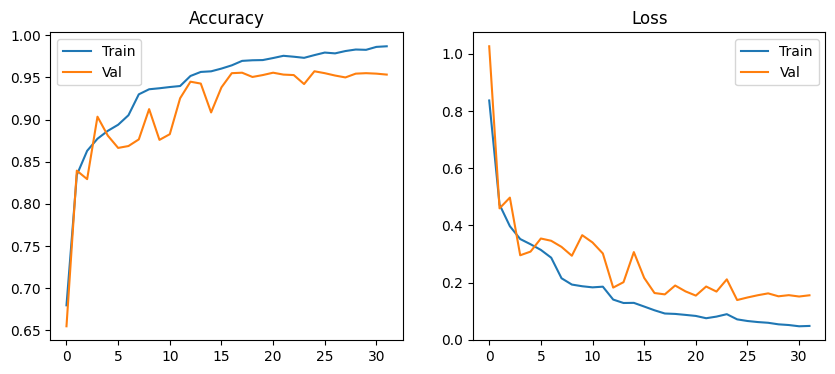

In [ ]:
#Training curve
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()

56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step


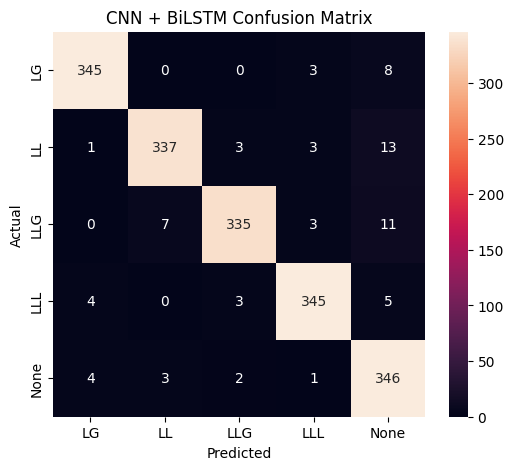

In [ ]:
#Confusion Matrix
y_pred = model.predict(X_test)
y_pred_cls = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred_cls)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=["LG","LL","LLG","LLL","None"],
            yticklabels=["LG","LL","LLG","LLL","None"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN + BiLSTM Confusion Matrix")
plt.show()

In [ ]:
#Confusion Report
print(classification_report(
    y_true,
    y_pred_cls,
    target_names=["LG","LL","LLG","LLL","None"]
))

              precision    recall  f1-score   support

          LG       0.97      0.97      0.97       356
          LL       0.97      0.94      0.96       357
         LLG       0.98      0.94      0.96       356
         LLL       0.97      0.97      0.97       357
        None       0.90      0.97      0.94       356

    accuracy                           0.96      1782
   macro avg       0.96      0.96      0.96      1782
weighted avg       0.96      0.96      0.96      1782



In [ ]:
model.save("/content/drive/My Drive/Datasets/cnn_bilstm_model.keras")